In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.precision', 4)

In [2]:
COLS = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation',
        'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
TARGET = 'income'

def load(path):
    df = pd.read_csv(path, names=COLS, skipinitialspace=True, na_values='?', comment='|')
    df[TARGET] = df[TARGET].str.rstrip('.')
    return df.dropna().drop(columns=['fnlwgt', 'education']).reset_index(drop=True)

train_df = load('adult.data')
test_df = load('adult.test')
X_train, y_train = train_df.drop(columns=TARGET), train_df[TARGET]
X_test, y_test = test_df.drop(columns=TARGET), test_df[TARGET]
print(train_df.shape, test_df.shape)

(30162, 13) (15060, 13)


In [3]:
def entropy(c):
    n = c.sum(-1, keepdims=True)
    p = np.divide(c, n, out=np.zeros(c.shape), where=n > 0)
    return -(p * np.log2(np.where(p > 0, p, 1))).sum(-1)

def gini(c):
    n = c.sum(-1, keepdims=True)
    p = np.divide(c, n, out=np.zeros(c.shape), where=n > 0)
    return 1 - (p ** 2).sum(-1)

def weighted_impurity(f, children):
    n = children.sum(-1)
    return (n / n.sum(-1, keepdims=True) * f(children)).sum(-1)

def split_info(children):
    return entropy(children.sum(-1))


class Encoder:
    def __init__(self, X, y):
        self.classes = np.unique(y)
        self.numeric = {c: pd.api.types.is_numeric_dtype(X[c]) for c in X.columns}
        self.cats = {c: X[c].astype('category').cat.categories for c in X.columns if not self.numeric[c]}

    def transform(self, X):
        return {c: X[c].to_numpy(float) if self.numeric[c]
                else pd.Categorical(X[c], categories=self.cats[c]).codes.astype(np.int64) for c in X.columns}

    def target(self, y):
        return np.searchsorted(self.classes, np.asarray(y))


class Node:
    def __init__(self, counts):
        self.counts = counts
        self.pred = counts.argmax()
        self.attr = self.threshold = self.codes = None
        self.children = {}

    @property
    def is_leaf(self):
        return not self.children


class DecisionTree:
    CRITERIA = {'gain': 'Information gain', 'gain_ratio': 'Gain ratio', 'gini': 'Gini index'}

    def __init__(self, criterion='gain', max_depth=8, min_samples_split=50, min_gain=1e-3, feature_sampler=None):
        assert criterion in self.CRITERIA
        self.criterion = criterion
        self.impurity = gini if criterion == 'gini' else entropy
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_gain = min_gain
        self.feature_sampler = feature_sampler

    def fit(self, X, y, sample_weight=None):
        enc = Encoder(X, y)
        return self.fit_encoded(enc, enc.transform(X), enc.target(y), sample_weight)

    def fit_encoded(self, enc, cols, y, sample_weight=None):
        self.enc, self.k = enc, len(enc.classes)
        w = np.ones(len(y)) if sample_weight is None else np.asarray(sample_weight, float)
        self.root = self._build(cols, y, w, np.nonzero(w > 0)[0], 0)
        return self

    def _score(self, parent, children):
        gain = self.impurity(parent) - weighted_impurity(self.impurity, children)
        if self.criterion == 'gain_ratio':
            si = split_info(children)
            return gain, np.divide(gain, si, out=np.zeros_like(gain), where=si > 0)
        return gain, gain

    def _split_numeric(self, x, y, w, parent):
        order = np.argsort(x, kind='stable')
        xs = x[order]
        cum = np.cumsum(np.eye(self.k)[y[order]] * w[order][:, None], axis=0)
        pos = np.nonzero(xs[1:] != xs[:-1])[0]
        if len(pos) == 0:
            return None
        left = cum[pos]
        children = np.stack([left, np.clip(parent - left, 0, None)], axis=1)
        gain, score = self._score(parent, children)
        i = gain.argmax() if self.criterion == 'gain_ratio' else score.argmax()
        return gain[i], score[i], (xs[pos[i]] + xs[pos[i] + 1]) / 2

    def _split_categorical(self, x, y, w, parent):
        children = np.bincount(x * self.k + y, weights=w, minlength=(x.max() + 1) * self.k).reshape(-1, self.k)
        children = children[children.sum(1) > 0]
        if len(children) < 2:
            return None
        gain, score = self._score(parent, children[None])
        return gain[0], score[0], None

    def _build(self, cols, y, w, idx, depth):
        parent = np.bincount(y[idx], weights=w[idx], minlength=self.k)
        node = Node(parent)
        if depth >= self.max_depth or len(idx) < self.min_samples_split or (parent > 0).sum() < 2:
            return node
        attrs = list(cols) if self.feature_sampler is None else self.feature_sampler(list(cols))
        cands = []
        for c in attrs:
            split_fn = self._split_numeric if self.enc.numeric[c] else self._split_categorical
            split = split_fn(cols[c][idx], y[idx], w[idx], parent)
            if split is not None and split[0] > self.min_gain:
                cands.append((c, *split))
        if not cands:
            return node
        if self.criterion == 'gain_ratio':
            avg = np.mean([g for _, g, _, _ in cands])
            cands = [s for s in cands if s[1] >= avg - 1e-12]
        attr, _, _, thr = max(cands, key=lambda s: s[2])
        node.attr, node.threshold = attr, thr
        x = cols[attr][idx]
        if thr is not None:
            parts = {'<= %g' % thr: idx[x <= thr], '> %g' % thr: idx[x > thr]}
        else:
            node.codes = np.unique(x)
            parts = {self.enc.cats[attr][v]: idx[x == v] for v in node.codes}
        node.children = {k: self._build(cols, y, w, v, depth + 1) for k, v in parts.items()}
        return node

    def predict(self, X):
        return self.enc.classes[self.predict_encoded(self.enc.transform(X))]

    def predict_encoded(self, cols):
        n = len(next(iter(cols.values())))
        out = np.empty(n, dtype=int)
        self._predict(self.root, cols, np.arange(n), out)
        return out

    def _predict(self, node, cols, idx, out):
        if node.is_leaf or len(idx) == 0:
            out[idx] = node.pred
            return
        x = cols[node.attr][idx]
        if node.threshold is not None:
            masks = [x <= node.threshold, x > node.threshold]
        else:
            masks = [x == v for v in node.codes]
        covered = np.zeros(len(idx), bool)
        for child, m in zip(node.children.values(), masks):
            self._predict(child, cols, idx[m], out)
            covered |= m
        out[idx[~covered]] = node.pred

In [4]:
class Ensemble:
    NAME = None
    TREE_DEFAULTS = {}

    def __init__(self, n_estimators=50, seed=42, **tree_params):
        self.n_estimators = n_estimators
        self.seed = seed
        self.tree_params = {**self.TREE_DEFAULTS, **tree_params}

    def fit(self, X, y):
        self.enc = Encoder(X, y)
        self.rng = np.random.default_rng(self.seed)
        self.members, self.alphas = [], []
        self._fit(self.enc.transform(X), self.enc.target(y))
        return self

    def _fit(self, cols, y):
        for _ in range(self.n_estimators):
            self.members.append(self._fit_member(cols, y))
            self.alphas.append(1.0)

    def _new_tree(self):
        return DecisionTree(**self.tree_params)

    def staged_predict(self, X, sizes):
        cols = self.enc.transform(X)
        votes = np.zeros((len(X), len(self.enc.classes)))
        rows = np.arange(len(X))
        out = {}
        for i, (tree, a) in enumerate(zip(self.members, self.alphas), 1):
            votes[rows, tree.predict_encoded(cols)] += a
            if i in sizes:
                out[i] = self.enc.classes[votes.argmax(1)]
        for s in sizes:
            out.setdefault(s, self.enc.classes[votes.argmax(1)])
        return out

    def predict(self, X, n=None):
        n = n or len(self.members)
        return self.staged_predict(X, [n])[n]


class Bagging(Ensemble):
    NAME = 'Бэггинг'
    TREE_DEFAULTS = dict(criterion='gini', max_depth=10, min_samples_split=20, min_gain=1e-4)

    def _fit_member(self, cols, y):
        w = np.bincount(self.rng.integers(0, len(y), len(y)), minlength=len(y))
        return self._new_tree().fit_encoded(self.enc, cols, y, w)


class RandomForest(Bagging):
    NAME = 'Случайный лес'

    def __init__(self, n_estimators=50, seed=42, max_features='sqrt', **tree_params):
        super().__init__(n_estimators, seed, **tree_params)
        self.max_features = max_features

    def _new_tree(self):
        return DecisionTree(**self.tree_params, feature_sampler=self._sample_features)

    def _sample_features(self, attrs):
        k = int(np.sqrt(len(attrs))) if self.max_features == 'sqrt' else self.max_features
        return list(self.rng.choice(attrs, max(1, k), replace=False))


class AdaBoost(Ensemble):
    NAME = 'Бустинг (AdaBoost)'
    TREE_DEFAULTS = dict(criterion='gini', max_depth=3, min_samples_split=20, min_gain=1e-4)

    def __init__(self, n_estimators=50, seed=42, learning_rate=0.5, **tree_params):
        super().__init__(n_estimators, seed, **tree_params)
        self.learning_rate = learning_rate

    def _fit(self, cols, y):
        w = np.ones(len(y))
        for _ in range(self.n_estimators):
            tree = self._new_tree().fit_encoded(self.enc, cols, y, w)
            miss = tree.predict_encoded(cols) != y
            err = w[miss].sum() / w.sum()
            if err >= 0.5:
                break
            alpha = self.learning_rate * np.log((1 - err) / max(err, 1e-10))
            self.members.append(tree)
            self.alphas.append(alpha)
            if err == 0:
                break
            w = w * np.exp(alpha * miss)
            w *= len(y) / w.sum()


TECHNIQUES = {'bagging': Bagging, 'random_forest': RandomForest, 'boosting': AdaBoost}

In [5]:
def metrics(y_true, y_pred, positive='>50K'):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = np.sum((y_pred == positive) & (y_true == positive))
    fp = np.sum((y_pred == positive) & (y_true != positive))
    fn = np.sum((y_pred != positive) & (y_true == positive))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {'accuracy': np.mean(y_true == y_pred), 'precision': precision, 'recall': recall, 'f1': f1}


def classify(train, test, technique, n_estimators, target=TARGET, **params):
    model = TECHNIQUES[technique](n_estimators, **params).fit(train.drop(columns=target), train[target])
    return model, metrics(test[target], model.predict(test.drop(columns=target)))

In [6]:
LAB3_PARAMS = dict(max_depth=8, min_samples_split=50, min_gain=1e-3)

baseline = {}
for crit, name in DecisionTree.CRITERIA.items():
    tree = DecisionTree(crit, **LAB3_PARAMS).fit(X_train, y_train)
    baseline[name] = metrics(y_test, tree.predict(X_test))
baseline = pd.DataFrame(baseline).T
baseline

,accuracy,precision,recall,f1
Information gain,0.8449,0.7286,0.5876,0.6505
Gain ratio,0.8544,0.7502,0.6105,0.6732
Gini index,0.8464,0.7254,0.6032,0.6587


In [7]:
SIZES = list(range(50, 101, 10))

rows, models = [], {}
for tech, cls in TECHNIQUES.items():
    start = time.perf_counter()
    model, _ = classify(train_df, test_df, tech, max(SIZES))
    print(f'{cls.NAME}: {len(model.members)} участников, {time.perf_counter() - start:.0f} с')
    models[tech] = model
    for n, pred in model.staged_predict(X_test, SIZES).items():
        rows.append({'technique': cls.NAME, 'n_estimators': n, **metrics(y_test, pred)})
results = pd.DataFrame(rows)
results.pivot(index='n_estimators', columns='technique')

Бэггинг: 100 участников, 67 с
Случайный лес: 100 участников, 23 с
Бустинг (AdaBoost): 100 участников, 7 с


accuracy                                precision  \
technique    Бустинг (AdaBoost) Бэггинг Случайный лес Бустинг (AdaBoost)   
n_estimators                                                               
50                       0.8561  0.8523        0.8590             0.7546   
60                       0.8567  0.8510        0.8595             0.7582   
70                       0.8565  0.8511        0.8591             0.7545   
80                       0.8570  0.8518        0.8598             0.7567   
90                       0.8577  0.8516        0.8592             0.7584   
100                      0.8581  0.8517        0.8593             0.7594   

                                               recall                        \
technique    Бэггинг Случайный лес Бустинг (AdaBoost) Бэггинг Случайный лес   
n_estimators                                                                  
50            0.7396        0.7717             0.6141  0.6157        0.6049   
60            0.7356        0.7720             0.6119  0.6143        0.6076   
70            0.7357        0.7687             0.6165  0.6146        0.6100   
80            0.7382        0.7700             0.6162  0.6149        0.6124   
90            0.7365        0.7682             0.6176  0.6165        0.6116   
100           0.7374        0.7684             0.6184  0.6154        0.6116   

                             f1                        
technique    Бустинг (AdaBoost) Бэггинг Случайный лес  
n_estimators                                           
50                       0.6771  0.6720        0.6782  
60                       0.6772  0.6695        0.6800  
70                       0.6786  0.6697        0.6802  
80                       0.6793  0.6709        0.6822  
90                       0.6808  0.6712        0.6810  
100                      0.6817  0.6709        0.6811

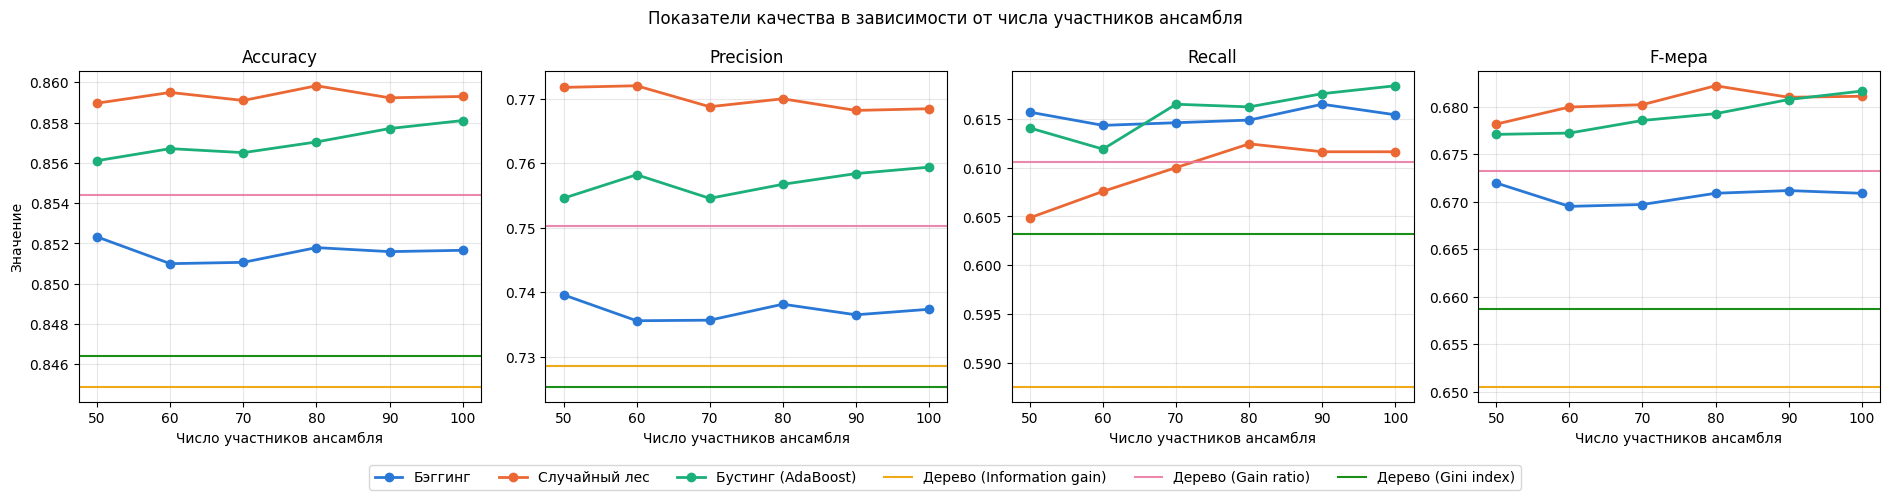

In [8]:
METRICS = {'accuracy': 'Accuracy', 'precision': 'Precision', 'recall': 'Recall', 'f1': 'F-мера'}
ENSEMBLE_COLORS = dict(zip(results['technique'].unique(), ['#2a78d6', '#eb6834', '#1baf7a']))
TREE_COLORS = dict(zip(baseline.index, ['#eda100', '#e87ba4', '#008300']))

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, (m, title) in zip(axes, METRICS.items()):
    for tech, grp in results.groupby('technique', sort=False):
        ax.plot(grp['n_estimators'], grp[m], marker='o', ms=6, lw=2, color=ENSEMBLE_COLORS[tech], label=tech)
    for name, color in TREE_COLORS.items():
        ax.axhline(baseline.loc[name, m], color=color, lw=1.5, alpha=0.9, label=f'Дерево ({name})')
    ax.set_title(title)
    ax.set_xlabel('Число участников ансамбля')
    ax.set_xticks(SIZES)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Значение')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.08))
plt.suptitle('Показатели качества в зависимости от числа участников ансамбля')
plt.tight_layout()
fig.savefig('metrics_by_metric.png', dpi=150, bbox_inches='tight')
plt.show()

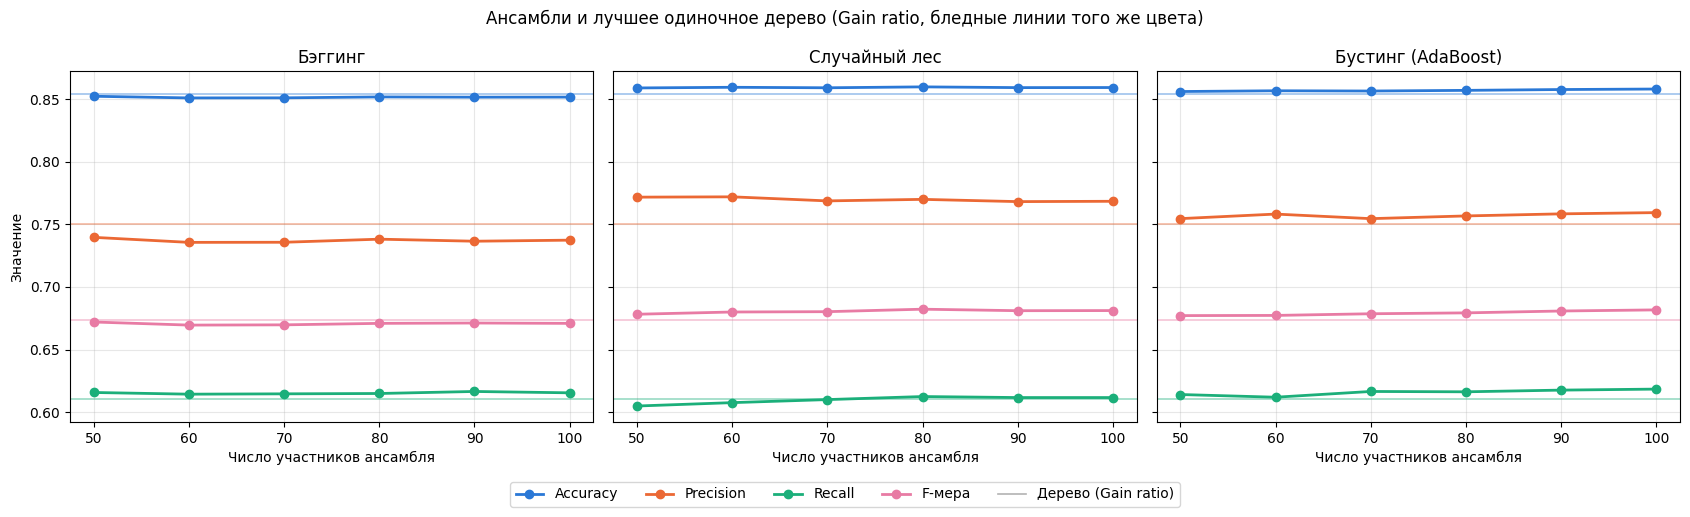

In [9]:
best = baseline['accuracy'].idxmax()
METRIC_COLORS = dict(zip(METRICS, ['#2a78d6', '#eb6834', '#1baf7a', '#e87ba4']))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, (tech, grp) in zip(axes, results.groupby('technique', sort=False)):
    for m, title in METRICS.items():
        color = METRIC_COLORS[m]
        ax.plot(grp['n_estimators'], grp[m], marker='o', ms=6, lw=2, color=color, label=title)
        ax.axhline(baseline.loc[best, m], color=color, lw=1.2, alpha=0.45)
    ax.set_title(tech)
    ax.set_xlabel('Число участников ансамбля')
    ax.set_xticks(SIZES)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Значение')
handles, labels = axes[0].get_legend_handles_labels()
handles.append(plt.Line2D([], [], color='gray', lw=1.2, alpha=0.6))
labels.append(f'Дерево ({best})')
fig.legend(handles, labels, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.07))
plt.suptitle(f'Ансамбли и лучшее одиночное дерево ({best}, бледные линии того же цвета)')
plt.tight_layout()
fig.savefig('metrics_by_technique.png', dpi=150, bbox_inches='tight')
plt.show()